In [1]:
#Define commands
import serial
import time


CMD_SET_CLK_EN              = b'\x11'  
CMD_GET_CLK_EN              = b'\x12'
CMD_GET_LOCKED              = b'\x15'
CMD_GET_CLKS_COUNTER        = b'\x18'

CMD_GET_TEMP_REG            = b'\x22'
CMD_GET_VINT_REG            = b'\x23'
CMD_GET_V1P8_REG            = b'\x25'
CMD_GET_V2P5_REG            = b'\x26'

CMD_SET_RO_EN               = b'\x28' 
CMD_GET_RO_EN               = b'\x29'
CMD_SET_RO_COUNT_EN         = b'\x2A' 
CMD_GET_RO_COUNT_EN         = b'\x2B'
CMD_GET_RO_COUNTER          = b'\x2C' 


def open_serial_device(serial_dev: str, baudrate: int, timeout: float) -> serial.Serial:
    ser: serial.Serial = serial.Serial(serial_dev, baudrate, timeout=timeout)
    return ser

def close_serial_device(ser: serial.Serial):
    ser.close()

def get_vccint(ser: serial.Serial) -> int:
    ser.write(CMD_GET_VINT_REG)
    response = ser.read(2)
    return int.from_bytes(response, 'big')

def get_vcc1p8(ser: serial.Serial) -> int:
    ser.write(CMD_GET_V1P8_REG)
    response = ser.read(2)
    return int.from_bytes(response, 'big')

def get_vcc2p5(ser: serial.Serial) -> int:
    ser.write(CMD_GET_V2P5_REG)
    response = ser.read(2)
    return int.from_bytes(response, 'big')

def get_temp(ser: serial.Serial) -> int:
    ser.write(CMD_GET_TEMP_REG)
    response = ser.read(2)
    return int.from_bytes(response, 'big')


def get_clk_en(ser: serial.Serial) -> int:
    ser.write(CMD_GET_CLK_EN)
    response = ser.read(1)
    return int.from_bytes(response, 'big')

def set_clk_en(ser: serial.Serial, value: int):
    ser.write(CMD_SET_CLK_EN)
    ser.write(value.to_bytes(1, 'big'))
    
def get_ro_en(ser: serial.Serial) -> int:
    ser.write(CMD_GET_RO_EN)
    response = ser.read(1)
    return int.from_bytes(response, 'big')
def set_ro_en(ser: serial.Serial, value: int):
    ser.write(CMD_SET_RO_EN)
    ser.write(value.to_bytes(1, 'big'))
    
def get_ro_counter(ser: serial.Serial) -> int:
    ser.write(CMD_GET_RO_COUNTER)
    response = ser.read(4)
    return int.from_bytes(response, 'big')
    
def get_ro_count_en(ser: serial.Serial) -> int:
    ser.write(CMD_GET_RO_COUNT_EN)
    response = ser.read(1)
    return int.from_bytes(response, 'big')

def set_ro_count_en(ser: serial.Serial, value: int):
    ser.write(CMD_SET_RO_COUNT_EN)
    ser.write(value.to_bytes(1, 'big'))


def get_locked(ser: serial.Serial) -> int:
    ser.write(CMD_GET_LOCKED)
    response = ser.read(1)
    return int.from_bytes(response, 'big')


def get_clocks_counter(ser: serial.Serial) -> int:
    ser.write(CMD_GET_CLKS_COUNTER)
    response = ser.read(2)
    return int.from_bytes(response, 'big')


In [2]:
# close_serial_device(fpga_ser)

In [3]:
import sys
import numpy as np
import time
#UART settings
fpga_ser = open_serial_device(serial_dev="COM3", baudrate=115200, timeout=1)
time.sleep(.1)


In [4]:

import logging
import time
from datetime import datetime

def tvs_temp_celsius(raw16: int) -> float:
    """
    Convert PolarFire TVS 16-bit temperature VALUE to Celsius.
    raw16: integer from 0x0000 to 0xFFFF
    """
    raw16 &= 0xFFFF

    temp_k = (raw16 & 0x7FFF) / 16.0   # bits [14:4] integer, [3:0] fraction
    temp_c = temp_k - 273.15

    return temp_c

def tvs_voltage_volts(raw16: int) -> float:
    """
    Convert PolarFire TVS 16-bit voltage VALUE to volts.
    raw16: integer from 0x0000 to 0xFFFF
    """
    raw16 &= 0xFFFF

    sign = -1 if (raw16 & 0x8000) else 1
    magnitude_mv = (raw16 & 0x7FFF) / 8.0  # bits [14:3] integer, [2:0] fraction

    voltage_v = sign * magnitude_mv / 1000.0

    return voltage_v


log_filename = datetime.now().strftime("fpga_log_%Y-%m-%d_%H-%M-%S.log")
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    handlers=[
        logging.FileHandler(log_filename, mode="w"),
        logging.StreamHandler()
    ],
    force=True,  
)

log = logging.getLogger(__name__)


iteration = 0
N = 300 #number of traces

start_time = time.time()

# initializing
set_clk_en(fpga_ser, 255)
time.sleep(.02)
log.info("CLK EN = %s", get_clk_en(fpga_ser))
time.sleep(.02)

time.sleep(.02)
log.info("locked = %s", get_locked(fpga_ser))

time.sleep(.02)
set_ro_en(fpga_ser, 255)  #always running
time.sleep(.02)
log.info("ro en = %s", get_ro_en(fpga_ser))

time.sleep(.02)
set_ro_count_en(fpga_ser, 0)
time.sleep(.02)
log.info("ro counter en = %s", get_ro_count_en(fpga_ser))

time.sleep(.02)

while (iteration < N):
    elapsed = time.time() - start_time
    log.info("iteration = %d (elapsed = %.3f s)", iteration, elapsed)

    #TVS values
    temp_raw = get_temp(fpga_ser)
    time.sleep(0.1)
    vccint_val = get_vccint(fpga_ser)
    time.sleep(0.1)
    vcc1p8_val = get_vcc1p8(fpga_ser)
    time.sleep(0.1)
    vcc2p5_val = get_vcc2p5(fpga_ser)
    time.sleep(0.1)
    t = tvs_temp_celsius(temp_raw)
    v = tvs_voltage_volts(vccint_val)
    v1p8 = tvs_voltage_volts(vcc1p8_val)
    v2p5 = tvs_voltage_volts(vcc2p5_val)
    log.info("temp = %.2f C", t)
    log.info("get_vccint = %s V", v)
    log.info("get_vcc1p8 = %s V", v1p8)
    log.info("get_vcc2p5 = %s V", v2p5)
    
    #RO Counter Values
    set_ro_count_en(fpga_ser, 255)
    time.sleep(0.02)
    log.info("get_ro_count_en = %s", get_ro_count_en(fpga_ser))
    time.sleep(0.1)
    log.info("get_ro_counter = %s", get_ro_counter(fpga_ser))
    time.sleep(0.1)
    set_ro_count_en(fpga_ser, 0)
    time.sleep(0.1)
    log.info("get_ro_count_en = %s", get_ro_count_en(fpga_ser))
    time.sleep(0.02)

    log.info("locked = %s", get_locked(fpga_ser))
    time.sleep(.02)

    #Clock Counter Values - we used only clk1 and clk3 for plotting 
    val = get_clocks_counter(fpga_ser)
    time.sleep(.1)
    clk1 = (val >> 12) & 0xF   # bits 15:12 
    clk2 = (val >> 8)  & 0xF   # bits 11:8
    clk3 = (val >> 4)  & 0xF   # bits 7:4   
    clk4 =  val        & 0xF   # bits 3:0 
    log.info("clk1 = %s", hex(clk1))
    log.info("clk2 = %s", hex(clk2))
    log.info("clk3 = %s", hex(clk3))
    log.info("clk4 = %s", hex(clk4))
    
    iteration += 1

close_serial_device(fpga_ser)   

2026-06-16 18:30:07,717 - INFO - CLK EN = 255
2026-06-16 18:30:07,796 - INFO - locked = 255
2026-06-16 18:30:07,844 - INFO - ro en = 255
2026-06-16 18:30:07,909 - INFO - ro counter en = 0
2026-06-16 18:30:07,948 - INFO - iteration = 0 (elapsed = 0.265 s)
2026-06-16 18:30:08,425 - INFO - temp = 49.79 C
2026-06-16 18:30:08,426 - INFO - get_vccint = 1.006 V
2026-06-16 18:30:08,428 - INFO - get_vcc1p8 = 1.818875 V
2026-06-16 18:30:08,429 - INFO - get_vcc2p5 = 2.5 V
2026-06-16 18:30:08,485 - INFO - get_ro_count_en = 255
2026-06-16 18:30:08,597 - INFO - get_ro_counter = 3097552
2026-06-16 18:30:08,829 - INFO - get_ro_count_en = 0
2026-06-16 18:30:08,863 - INFO - locked = 255
2026-06-16 18:30:08,996 - INFO - clk1 = 0x7
2026-06-16 18:30:08,998 - INFO - clk2 = 0xa
2026-06-16 18:30:09,000 - INFO - clk3 = 0x7
2026-06-16 18:30:09,002 - INFO - clk4 = 0xa
2026-06-16 18:30:09,005 - INFO - iteration = 1 (elapsed = 1.322 s)
2026-06-16 18:30:09,476 - INFO - temp = 49.10 C
2026-06-16 18:30:09,477 - INFO 

fpga_log_2026-06-16_18-30-07.log


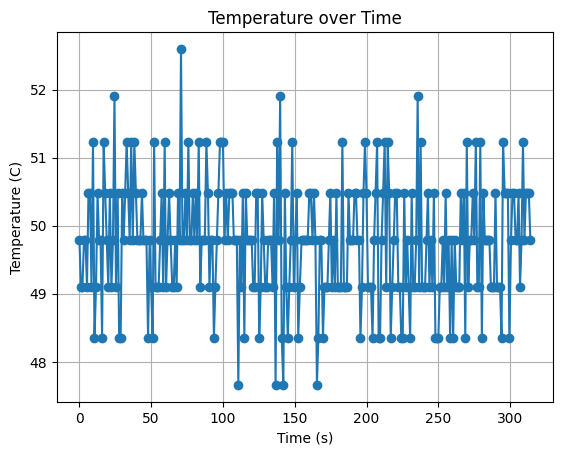

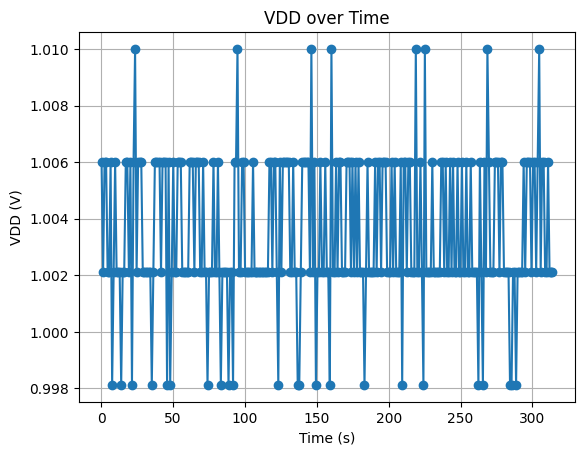

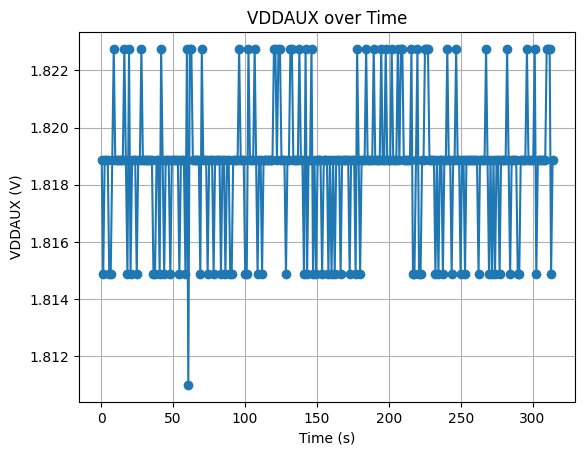

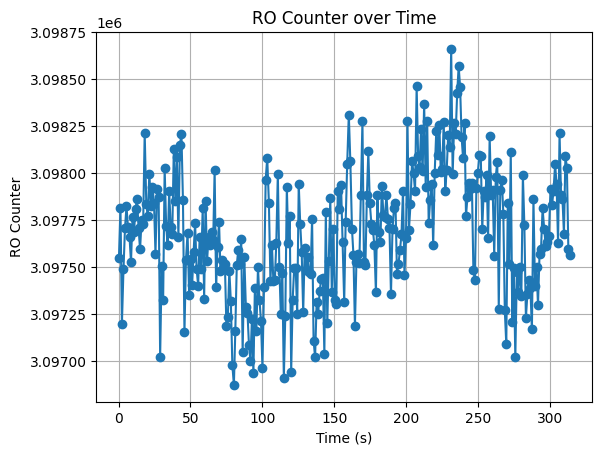

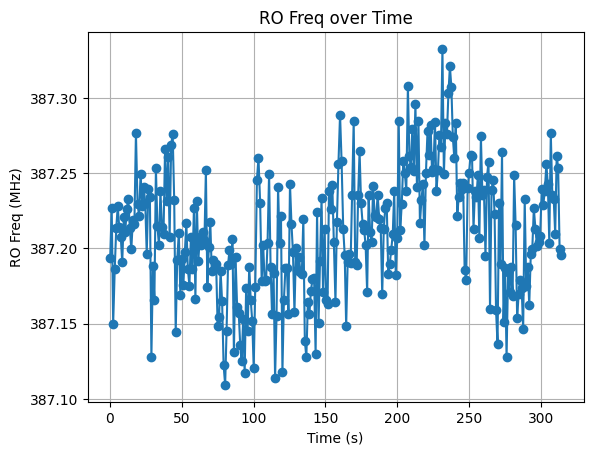

In [5]:
import re
import matplotlib.pyplot as plt

LOG_FILE = log_filename
print(LOG_FILE)

iter_re   = re.compile(r"iteration = (\d+) \(elapsed = ([0-9.]+) s\)")
temp_re = re.compile(r"temp\s*=\s*([+-]?\d+(?:\.\d+)?)\s*C", re.IGNORECASE)
vcc_re    = re.compile(r"get_vccint = ([0-9.]+) V")
vaux_re    = re.compile(r"get_vcc1p8 = ([0-9.]+) V")
ro_re     = re.compile(r"get_ro_counter = ([0-9.]+)")



temp_time, temp_vals         = [], []
vcc_time, vcc_vals           = [], []
vaux_time, vaux_vals         = [], []
ro_time, ro_vals             = [], []

current_elapsed = None  

with open(LOG_FILE, "r") as f:
    for line in f:
        m_iter = iter_re.search(line)
        if m_iter:
            current_elapsed = float(m_iter.group(2))
            continue

        if current_elapsed is None:
            continue

        # Temperature
        m_temp = temp_re.search(line)
        if m_temp:
            temp_time.append(current_elapsed)
            temp_vals.append(float(m_temp.group(1)))
            continue

        # VCCINT
        m_vcc = vcc_re.search(line)
        if m_vcc:
            vcc_time.append(current_elapsed)
            vcc_vals.append(float(m_vcc.group(1)))
            continue
        # VCCAUX
        m_vaux = vaux_re.search(line)
        if m_vaux:
            vaux_time.append(current_elapsed)
            vaux_vals.append(float(m_vaux.group(1)))
            continue

        # RO counter
        m_ro = ro_re.search(line)
        if m_ro:
            ro_time.append(current_elapsed)
            ro_vals.append(float(m_ro.group(1)))
            continue


# ----------------- Plotting -----------------
# Temp over time
if temp_time:
    plt.figure()
    plt.plot(temp_time, temp_vals, marker = 'o')
    plt.xlabel("Time (s)")
    plt.ylabel("Temperature (C)")
    plt.title("Temperature over Time")
    
    plt.grid(True)

# VCCINT over time
if vcc_time:
    plt.figure()
    plt.plot(vcc_time, vcc_vals,marker = 'o')
    plt.xlabel("Time (s)")
    plt.ylabel("VDD (V)")
    plt.title("VDD over Time")
    plt.grid(True)
    
# VCCAUX over time
if vaux_time:
    plt.figure()
    plt.plot(vaux_time, vaux_vals,marker = 'o')
    plt.xlabel("Time (s)")
    plt.ylabel("VDDAUX (V)")
    plt.title("VDDAUX over Time")
    plt.grid(True)

# RO counter over time
if ro_time:
    plt.figure()
    plt.plot(ro_time, ro_vals,marker = 'o')
    plt.xlabel("Time (s)")
    plt.ylabel("RO Counter")
    plt.title("RO Counter over Time")
    plt.grid(True)
    
# RO freq over time
ro_freq = []
for i in range(len(ro_vals)):
    ro_freq.append((ro_vals[i]/100000)*12.5)
if ro_time:
    plt.figure()
    plt.plot(ro_time, ro_freq,marker = 'o')
    plt.xlabel("Time (s)")
    plt.ylabel("RO Freq (MHz)")
    plt.title("RO Freq over Time")
    plt.grid(True)


plt.show()


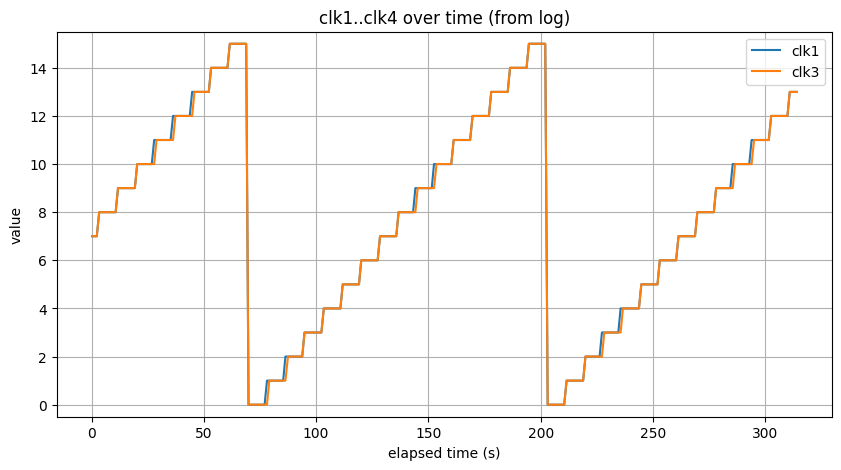

In [6]:
import re
import pandas as pd
import matplotlib.pyplot as plt

log_path = log_filename; 

# Regex patterns
re_elapsed = re.compile(r"iteration\s*=\s*(\d+)\s*\(elapsed\s*=\s*([0-9.]+)\s*s\)", re.IGNORECASE)
re_clk = re.compile(r"clk([1-4])\s*=\s*(0x[0-9a-fA-F]+|\d+)", re.IGNORECASE)

rows = []
cur = {"iteration": None, "elapsed_s": None, "clk1": None, "clk2": None, "clk3": None, "clk4": None}

def finalize_if_complete(cur_dict):
    # only save when we have time + all 4 clocks
    if cur_dict["elapsed_s"] is not None and all(cur_dict[f"clk{i}"] is not None for i in range(1, 5)):
        rows.append(cur_dict.copy())

with open(log_path, "r", encoding="utf-8", errors="ignore") as f:
    for line in f:
        m = re_elapsed.search(line)
        if m:
            # if previous iteration was complete, store it
            finalize_if_complete(cur)

            # start a new record
            cur = {"iteration": int(m.group(1)),
                   "elapsed_s": float(m.group(2)),
                   "clk1": None, "clk2": None, "clk3": None, "clk4": None}
            continue

        m = re_clk.search(line)
        if m and cur["elapsed_s"] is not None:
            idx = int(m.group(1))
            val_str = m.group(2).strip()
            val_int = int(val_str, 16) if val_str.lower().startswith("0x") else int(val_str)
            cur[f"clk{idx}"] = val_int

# catch last record
finalize_if_complete(cur)

df = pd.DataFrame(rows).sort_values("elapsed_s").reset_index(drop=True)
# display(df.head(), df.tail())

# ---- plot ----
plt.figure(figsize=(10, 5))
plt.plot(df["elapsed_s"], df["clk1"], label="clk1")
# plt.plot(df["elapsed_s"], df["clk2"], label="clk2")
plt.plot(df["elapsed_s"], df["clk3"], label="clk3")
# plt.plot(df["elapsed_s"], df["clk4"], label="clk4")

plt.xlabel("elapsed time (s)")
plt.ylabel("value")
plt.title("clk1..clk4 over time (from log)")
plt.grid(True)
plt.legend()
plt.ylim(-0.5, 15.5)  # since your clk values are 0..15
plt.show()